# Is there an optimal τ under Selene's own noise model?

End to end in Selene: a surface-code memory, its real extraction circuit, Selene's native
depolarizing channels, and a spacetime decoder. No phenomenological parameters anywhere.

**The premise under test is unchanged** — can the trade-off between idling and measurement
error be optimised over? — but the terms are no longer ours to set:

| | `05` (Stim) | here (Selene) |
| --- | --- | --- |
| `p_stab` | a parameter we supply | whatever the extraction CNOTs do |
| `p_read` | a parameter we supply | `p_meas` **plus** ancilla gate error |
| λ | swept freely | fixed by the circuit |
| correlated data↔ancilla faults | cannot be expressed | ancilla faults propagate onto the data through the CNOTs; the two-qubit channel `p_2q` is off in this notebook |

`05` had to be *told* about `p_stab` before an interior optimum appeared. Selene is never told:
running the extraction circuit costs what it costs. **If the optimum is real rather than a
modelling choice, it should appear here without being put in.**

## Configuration

In [1]:
# ---- the knobs -------------------------------------------------------------
CODE       = "rotated"     # "rotated" | "unrotated"
DISTANCE   = 3             # 3 | 5 | 7   (qubit count grows fast: see the table below)

TOTAL_IDLE = 96            # wall-clock, HELD FIXED. rounds R = TOTAL_IDLE / tau
P_1Q       = 0.0005        # idling and every native 1q op, including inside each CNOT
P_2Q       = 0.0           # two-qubit channel: the data<->ancilla correlated fault
P_MEAS     = 0.002         # flip of the reported bit
SHOTS      = 10_000       # per replica
REPLICAS   = 5            # independent samples, taken via shot_offset
SATURATED  = 0.25          # above this pL the code has failed; comparisons are noise
# ----------------------------------------------------------------------------

SPEC = {"rotated": "surface_code:rotated_memory_z",
        "unrotated": "surface_code:unrotated_memory_z"}[CODE]

import pathlib, yaml
import numpy as np


def find_config(name):
    for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        p = base / "config" / name
        if p.exists():
            return p
    return None


# Two sources, and the difference lands directly on the decoder.
# 04_extraction_cost_surface.ipynb MEASURES the charged ops per round on this very
# circuit. 04_extraction_cost_steane.ipynb DERIVES them from Steane's per-CX conversion,
# which prices the CONTROL side of every CNOT -- while a surface data qubit is the TARGET
# of each of its X-checks. For rotated d=3 that is 2.658 ops against a measured 6.889, so
# the derived value understates the data-edge prior by 2.6x, and worst at small tau where
# the extraction cost dominates the tau idle ops. Prefer the measured file.
MEAS = find_config("surface_extraction_measured.yaml")
DER = find_config("extraction_constants.yaml")
KEY = f"{CODE}_d{DISTANCE}"

OPS_PER_DATA_QUBIT = None
if MEAS:
    _m = yaml.safe_load(MEAS.read_text())["surface_measured"][KEY]
    OPS_PER_DATA_QUBIT = np.array(_m["ops_per_round"]["data_per_qubit"], float)
    N_DATA_OPS = float(_m["ops_per_round"]["data_mean"])
    N_ANC_OPS = float(_m["ops_per_round"]["ancilla_z"])
    B_FLOOR = float(_m["b_read_floor"])
    SOURCE = f"measured -- {MEAS.name}"
elif DER:
    _e = yaml.safe_load(DER.read_text())["surface"][KEY]
    N_DATA_OPS, N_ANC_OPS = float(_e["n_data"]), float(_e["n_anc"])
    B_FLOOR = float(_e["b_read_floor"])
    SOURCE = f"DERIVED (2.6x low on the data side) -- {DER.name}"
else:
    N_DATA_OPS = N_ANC_OPS = B_FLOOR = None
    SOURCE = "none found -- run 04_extraction_cost_surface.ipynb first"

print(f"extraction constants: {SOURCE}")
if N_DATA_OPS:
    print(f"  charged ops per round: {N_DATA_OPS:.3f} per data qubit (mean), "
          f"{N_ANC_OPS:.3f} per Z-ancilla")
    print(f"  b_read floor {B_FLOOR:.3f}")
if OPS_PER_DATA_QUBIT is not None:
    print(f"  per-qubit spread: {OPS_PER_DATA_QUBIT.min():.2f} to "
          f"{OPS_PER_DATA_QUBIT.max():.2f} ops -- the decoder now weights each data edge "
          f"by its own cost")
    if DER:
        _d = yaml.safe_load(DER.read_text())["surface"][KEY]
        print(f"  (the derived values this notebook used to load: "
              f"{_d['n_data']} / {_d['n_anc']})")
print(f"\n{CODE} surface code, d={DISTANCE}, total idle {TOTAL_IDLE}, {SHOTS} shots")

extraction constants: measured -- surface_extraction_measured.yaml
  charged ops per round: 6.889 per data qubit (mean), 8.967 per Z-ancilla
  b_read floor 1.302
  per-qubit spread: 3.93 to 11.40 ops -- the decoder now weights each data edge by its own cost
  (the derived values this notebook used to load: 2.658 / 8.769)

rotated surface code, d=3, total idle 96, 10000 shots


## 1. Layout

The code geometry is read off a Stim circuit rather than written by hand: Stim defines which
data qubits each stabiliser touches, in which CNOT order, and which qubits carry the logical
observable. Selene then executes that same circuit under its own noise model.

Taking the CNOT *order* from Stim matters — the order is what decides how an ancilla fault
propagates back onto the data, and a hand-written order would silently change it.

In [2]:
%matplotlib inline
import pathlib

# Reference palette, fixed order. Slots 1-3 validate under all-pairs comparison.
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GRAY, INK, MUTED = '#8a8a86', '#0b0b0b', '#52514e'
import numpy as np, pandas as pd, stim, pymatching
from collections import defaultdict
import matplotlib.pyplot as plt
pd.set_option('display.width', 140)
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c9c9c4', 'axes.labelcolor': MUTED, 'axes.titlesize': 10,
    'axes.labelsize': 9, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'grid.color': '#e6e6e1',
    'legend.frameon': False, 'legend.fontsize': 8, 'font.size': 9, 'text.color': INK,
})
FIGDIR = pathlib.Path('figures'); FIGDIR.mkdir(exist_ok=True)


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGDIR / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()



def layout(spec, d):
    """Data qubits, Z/X stabiliser supports in CNOT order, and the logical support."""
    c = stim.Circuit.generated(spec, distance=d, rounds=1)
    anc, data_order, cx_pairs, obs = set(), [], [], []
    for inst in c.flattened():
        t = [g.value for g in inst.targets_copy() if g.is_qubit_target]
        if inst.name in ('CX', 'CNOT', 'ZCX'):
            cx_pairs += [(t[i], t[i + 1]) for i in range(0, len(t), 2)]
        elif inst.name in ('MR', 'MRZ'):
            anc.update(t)
        elif inst.name in ('M', 'MZ'):
            data_order = t
        elif inst.name == 'OBSERVABLE_INCLUDE':
            recs = [g.value for g in inst.targets_copy() if g.is_measurement_record_target]
            obs = [data_order[len(data_order) + r] for r in recs]
    data = [q for q in data_order if q not in anc]
    zsup, xsup = defaultdict(list), defaultdict(list)
    for ctrl, tgt in cx_pairs:
        if tgt in anc:
            zsup[tgt].append(ctrl)
        if ctrl in anc:
            xsup[ctrl].append(tgt)
    return dict(data=data, zanc=sorted(zsup), xanc=sorted(xsup),
                zsup=dict(zsup), xsup=dict(xsup), obs=obs, cx=cx_pairs)


L = layout(SPEC, DISTANCE)
N_DATA, N_ANC = len(L['data']), len(L['zanc']) + len(L['xanc'])
print(f"data {N_DATA}, Z-ancillas {len(L['zanc'])}, X-ancillas {len(L['xanc'])}, "
      f"total qubits {N_DATA + N_ANC}")
print(f"logical observable weight {len(L['obs'])} (should equal d = {DISTANCE})")
print(f"Z-stabiliser weights: {sorted({len(v) for v in L['zsup'].values()})}")
assert len(L['obs']) == DISTANCE


data 9, Z-ancillas 4, X-ancillas 4, total qubits 17
logical observable weight 3 (should equal d = 3)
Z-stabiliser weights: [2, 4]


## 2. The Guppy program

One round is: `τ` idle operations on every data qubit, then the full extraction circuit —
**both sectors**. Only the Z-checks are decoded, since those are what detect the X errors that
flip a `|0_L⟩` memory, but the X-checks still run and still cost, because a real surface code
round runs them. That is the honest per-round cost and it is why a data qubit sees ~4 CNOTs
rather than 2.

The program is generated as source text, because the CNOT list is data and Guppy has no way to
loop over a Python list of qubit indices. It is written to a real module file rather than
`exec`'d: Guppy parses the decorated function with `inspect.getsourcelines`, so a function
built from a string has no source to read and compilation fails outright.

Every round emits an `"s"` output. Selene returns each shot as a sequence of `(tag, value)`
pairs, so the rounds are recovered in order by reading the pairs rather than collapsing them
into a dict.

In [3]:
import importlib.util, pathlib, sys, tempfile

from guppylang import guppy
from guppylang.std.angles import angle
from guppylang.std.builtins import array, output, py
from guppylang.std.quantum import collect_measurements, cx, h, measure, measure_array, qubit
from guppylang.std.qsystem import phased_x
from selene_sim import DepolarizingErrorModel, Stim, build

DIDX = {q: i for i, q in enumerate(L['data'])}
AIDX = {q: i for i, q in enumerate(L['zanc'] + L['xanc'])}
XSET = set(L['xanc'])


def guppy_source(tau, rounds):
    """Emit the memory experiment as Guppy source."""
    o = ["@guppy", "def prog() -> None:",
         f"    qs = array(qubit() for _ in range(py({N_DATA})))",
         f"    for _ in range(py({rounds})):"]
    if tau:
        o += [f"        for _ in range(py({tau})):",
              f"            for i in range(py({N_DATA})):",
               "                phased_x(qs[i], angle(0.0), angle(0.0))"]
    o.append(f"        anc = array(qubit() for _ in range(py({N_ANC})))")
    o += [f"        h(anc[{AIDX[a]}])" for a in L['xanc']]
    for ctrl, tgt in L['cx']:
        cs = f"anc[{AIDX[ctrl]}]" if ctrl in AIDX else f"qs[{DIDX[ctrl]}]"
        ts = f"anc[{AIDX[tgt]}]" if tgt in AIDX else f"qs[{DIDX[tgt]}]"
        o.append(f"        cx({cs}, {ts})")
    o += [f"        h(anc[{AIDX[a]}])" for a in L['xanc']]
    # measure_array consumes the whole array at once. Guppy's linear types forbid
    # consuming a qubit out of an array by subscript -- measure(anc[i]) is rejected
    # because a subscript on a non-copyable type may only be borrowed.
    o.append('        output("s", collect_measurements(measure_array(anc)))')
    o.append('    output("data", collect_measurements(measure_array(qs)))')
    return "\n".join(o)


PREAMBLE = """from guppylang import guppy
from guppylang.std.angles import angle
from guppylang.std.builtins import array, output, py
from guppylang.std.quantum import collect_measurements, cx, h, measure, measure_array, qubit
from guppylang.std.qsystem import phased_x


"""

# Guppy parses the decorated function with inspect.getsourcelines, so the program must
# exist as real source on disk. exec()ing a string gives the function no source file and
# compilation dies with "could not get source code".
GEN_DIR = pathlib.Path(tempfile.mkdtemp(prefix='guppy_generated_'))
_BUILT = {}


def runner(tau, rounds):
    key = (tau, rounds)
    if key not in _BUILT:
        name = f'memory_t{tau}_r{rounds}'
        path = GEN_DIR / f'{name}.py'
        path.write_text(PREAMBLE + guppy_source(tau, rounds) + chr(10))
        spec = importlib.util.spec_from_file_location(name, path)
        mod = importlib.util.module_from_spec(spec)
        sys.modules[name] = mod
        spec.loader.exec_module(mod)
        _BUILT[key] = build(mod.prog.compile())
    return _BUILT[key]


def run(tau, rounds, shots=SHOTS, seed=1, offset=0, **ch):
    """Returns (syndromes [shots, rounds, N_ANC], data [shots, N_DATA])."""
    out = runner(tau, rounds).run_shots(
        simulator=Stim(), n_qubits=N_DATA + N_ANC, n_shots=shots,
        error_model=DepolarizingErrorModel(random_seed=seed, **ch), random_seed=seed,
        shot_offset=offset)
    syn, dat = [], []
    for shot in out:
        pairs = list(shot)
        s = [v for k, v in pairs if k == "s"]
        d = [v for k, v in pairs if k == "data"][0]
        syn.append([[int(b) for b in r] for r in s])
        dat.append([int(b) for b in d])
    return np.array(syn), np.array(dat)


print(guppy_source(1, 1)[:400], "\n...")


@guppy
def prog() -> None:
    qs = array(qubit() for _ in range(py(9)))
    for _ in range(py(1)):
        for _ in range(py(1)):
            for i in range(py(9)):
                phased_x(qs[i], angle(0.0), angle(0.0))
        anc = array(qubit() for _ in range(py(8)))
        h(anc[4])
        h(anc[5])
        h(anc[6])
        h(anc[7])
        cx(anc[4], qs[1])
        cx(anc[6], qs[7])
    
...


## 3. Does the circuit work with the noise off?

Noiseless, the **Z**-checks must read 0 and the logical observable must be 0: the data start
in `|0...0>`, a +1 eigenstate of every Z-stabiliser, and the final readout must be a codeword.

The **X**-checks must not read 0, and that is the point. `|0...0>` is not an X-stabiliser
eigenstate, so the first round *projects* the state into the code space and its X outcomes are
random — after which they must repeat exactly. A test demanding silence from every ancilla
would be testing the wrong thing and would fail on a correct circuit.

Only the Z sector is decoded, since Z-checks are what detect the X errors that flip a
`|0_L>` memory. If any of these fail, the generated circuit is wrong and nothing below means
anything.

In [4]:
ZCOLS = [AIDX[a] for a in L['zanc']]
ZSUP = [[DIDX[q] for q in L['zsup'][a]] for a in L['zanc']]
OBS = [DIDX[q] for q in L['obs']]


def observable(dat):
    return dat[:, OBS].sum(axis=1) % 2


def final_syndrome(dat):
    return np.array([dat[:, s].sum(axis=1) % 2 for s in ZSUP]).T


XCOLS = [AIDX[a] for a in L['xanc']]

syn, dat = run(2, 2, shots=200, p_1q=0.0, p_2q=0.0, p_meas=0.0)
z_bits, x_bits = syn[:, :, ZCOLS], syn[:, :, XCOLS]
x_repeats = bool((x_bits[:, 1:, :] == x_bits[:, :1, :]).all())

print("Z-ancilla bits set (noiseless):", int(z_bits.sum()))
print("final-readout syndrome set    :", int(final_syndrome(dat).sum()))
print("logical observable set        :", int(observable(dat).sum()))
print("X-ancilla bits set            :", int(x_bits.sum()), "- random BY DESIGN")
print("X-ancilla rounds repeat after the first:", x_repeats)

assert z_bits.sum() == 0, "Z-checks must be silent on |0...0>"
assert final_syndrome(dat).sum() == 0, "final readout must be a codeword"
assert observable(dat).sum() == 0, "logical observable must be 0"
assert x_repeats, "X-checks must be deterministic after the projecting round"
print("\ncircuit is correct with the noise off")


Z-ancilla bits set (noiseless): 0
final-readout syndrome set    : 0
logical observable set        : 0
X-ancilla bits set            : 800 - random BY DESIGN
X-ancilla rounds repeat after the first: True

circuit is correct with the noise off


## 4. Spacetime decoder

Steane could not be matched — an X on `q6` flips all three checks, a weight-3 hyperedge. A
surface code can: every X error touches at most two Z-checks.

Detectors are `D[j,c] = s[j,c] ⊕ s[j−1,c]`, with `s[−1] = 0` and a final layer computed from
the destructive readout. Two mechanisms, exactly as in the phenomenological picture, except
that here their probabilities are consequences rather than inputs:

- **data X error** in interval `j` → flips `D[j,c]` for the Z-checks containing that qubit
  (two in the bulk, one at a boundary → a boundary edge), and flips the observable if the
  qubit is in the logical support;
- **syndrome flip** of check `c` in round `j` → flips `D[j,c]` and `D[j+1,c]`, a time-like
  edge, and never touches the observable.

**Edge weights come from measured operation counts, per data qubit.**
`04_extraction_cost_surface.ipynb` measures what one round charges each individual data
qubit and each Z-ancilla on this circuit, so every data edge is weighted by its own cost
rather than by a block average. Two reasons that matters here:

- the per-qubit cost spans a factor of ~3 across the block, so one average misprices both
  ends of it;
- the data prior is `accumulate(ops + τ)`, in which the extraction term dominates at small
  τ and the idle term at large τ. An error in `ops` is therefore **τ-dependent**, largest
  exactly where §5b found the curve misbehaving.

The priors are still approximations — they treat each data qubit's fault as independent,
which the correlated data↔ancilla mechanism is not.

In [5]:
def detectors(syn, dat):
    """[shots, rounds+1, n_z] detector array."""
    s = syn[:, :, ZCOLS]                                  # [shots, rounds, n_z]
    s = np.concatenate([s, final_syndrome(dat)[:, None, :]], axis=1)
    prev = np.concatenate([np.zeros_like(s[:, :1, :]), s[:, :-1, :]], axis=1)
    return (s ^ prev).reshape(s.shape[0], -1)


def matching(rounds, p_d, p_m):
    """Spacetime matching graph.

    `p_d` is per data qubit (array of length N_DATA) or a scalar broadcast over all of
    them: each data edge carries the fault probability of its own qubit.
    """
    n_z = len(ZSUP)
    p_d = np.broadcast_to(np.asarray(p_d, dtype=float), (N_DATA,))
    m = pymatching.Matching()
    w = lambda p: float(np.log((1 - p) / max(p, 1e-9)))
    for j in range(rounds + 1):
        for qi in range(N_DATA):
            ch = [c for c, s in enumerate(ZSUP) if qi in s]
            f = {0} if qi in OBS else set()
            if len(ch) == 2:
                m.add_edge(j * n_z + ch[0], j * n_z + ch[1], fault_ids=f,
                           weight=w(p_d[qi]), merge_strategy="independent")
            elif len(ch) == 1:
                m.add_boundary_edge(j * n_z + ch[0], fault_ids=f,
                                    weight=w(p_d[qi]), merge_strategy="independent")
    for j in range(rounds):
        for c in range(n_z):
            m.add_edge(j * n_z + c, (j + 1) * n_z + c, fault_ids=set(),
                       weight=w(p_m), merge_strategy="independent")
    return m


def accumulate(n, f):
    """P(odd number of flips) after n charged operations."""
    return (1 - (1 - 2 * f) ** n) / 2


def priors(tau, p_1q, p_meas):
    """Edge weights the decoder should believe, from measured per-qubit op counts.

    Returns (per-qubit data fault probability, measurement fault probability).

    Two corrections over the first version. It passed `p_meas` straight in as the
    measurement prior, ignoring the ancilla's own gate faults, which dominate it. And it
    took the data cost from the DERIVED config, which prices the control side of every
    CNOT and so understates a surface data qubit by ~2.6x -- an error that is largest at
    small tau, because that is where the extraction term outweighs the tau idle ops.
    """
    f = 2 * p_1q / 3
    ops = OPS_PER_DATA_QUBIT if OPS_PER_DATA_QUBIT is not None else N_DATA_OPS
    p_d = accumulate(np.asarray(ops, dtype=float) + tau, f)   # extraction + tau idle ops
    p_anc = accumulate(N_ANC_OPS, f)                          # ancilla gate faults
    p_m = 1 - (1 - p_meas) * (1 - p_anc)                      # plus the readout flip
    return np.maximum(p_d, 1e-5), max(p_m, 1e-5)


import sys; sys.path.insert(0, '../src')   # qec_timing.circuit_level
from qec_timing.circuit_level import runcache

EXPERIMENT = '06_selene_interval'
# Bumped when the priors changed: the cache key has to record which decoder produced a
# result, or entries from the old per-block prior would be reused silently.
PRIOR_TAG = 'measured-per-qubit'
CACHE_HITS = {'hit': 0, 'miss': 0}


def one_replica(tau, rounds, offset, shots=SHOTS, **ch):
    """Failures and shots for one seed, cached on every parameter that affects it."""
    params = dict(code=CODE, distance=DISTANCE, total_idle=TOTAL_IDLE, tau=tau,
                  rounds=rounds, shots=shots, shot_offset=offset,
                  p_1q=ch.get('p_1q', 0.0), p_2q=ch.get('p_2q', 0.0),
                  p_meas=ch.get('p_meas', 0.0), decoder='pymatching',
                  priors=PRIOR_TAG)
    hit = runcache.load(EXPERIMENT, params)
    if hit is not None:
        CACHE_HITS['hit'] += 1
        return hit['failures'], hit['shots']

    syn, dat = run(tau, rounds, shots=shots, offset=offset, **ch)
    det = detectors(syn, dat)
    p_d, p_m = priors(tau, ch.get('p_1q', 0.0), ch.get('p_meas', 0.0))
    pred = matching(rounds, p_d, p_m).decode_batch(det.astype(np.uint8))[:, 0]
    fails = int(np.sum(pred != observable(dat)))
    runcache.save(EXPERIMENT, params,
                  {'failures': fails, 'shots': int(shots),
                   'pL': fails / shots,
                   'prior_data_mean': float(np.mean(p_d)), 'prior_meas': p_m})
    CACHE_HITS['miss'] += 1
    return fails, int(shots)


def logical_error(tau, rounds, shots=SHOTS, replicas=REPLICAS, **ch):
    """Pool independent seeds. Returns (pL, sigma, per-seed pL).

    Replicas are disjoint blocks of Selene's shot index, taken with `shot_offset`.
    `random_seed` does NOT vary the realisation in this version -- seeds 1-4 return
    an identical flip rate to four decimals on both backends -- so seeding would
    give five copies of one sample and a sigma too small by sqrt(5).

    Pooling failures rather than averaging rates keeps the binomial error honest,
    and the replica spread is the diagnostic: a systematic artefact repeats across
    replicas, sampling noise does not.
    """
    per_seed, F, N = [], 0, 0
    for k in range(replicas):
        f, n = one_replica(tau, rounds, k * shots, shots=shots, **ch)
        per_seed.append(f / n); F += f; N += n
    e = F / N
    return e, float(np.sqrt(max(e * (1 - e), 1e-12) / N)), per_seed


print("decoder wired; sanity (noiseless):",
      logical_error(2, 2, shots=200, replicas=1, p_1q=0.0, p_meas=0.0)[0])
_pd, _pm = priors(1, P_1Q, P_MEAS)
print(f"priors at tau=1: data {_pd.min():.5f}-{_pd.max():.5f} "
      f"(mean {_pd.mean():.5f}), meas {_pm:.5f}")

decoder wired; sanity (noiseless): 0.0
priors at tau=1: data 0.00164-0.00412 (mean 0.00262), meas 0.00498


## 5. The sweep

`TOTAL_IDLE` is held fixed, so `R = TOTAL_IDLE / τ`. Only values with `R ≥ d` are used — the
same validity condition `05` enforces, and the one the first version of that notebook violated.

Nothing here sets a per-round data cost. It is whatever the extraction CNOTs charge through
`p_1q`.

In [6]:
import time

TAUS = [t for t in range(1, TOTAL_IDLE + 1)
        if TOTAL_IDLE % t == 0 and TOTAL_IDLE // t >= DISTANCE]
print("tau grid:", TAUS, " rounds:", [TOTAL_IDLE // t for t in TAUS], "\n")

t0 = time.time()
vals, errs = [], []
PER_SEED = {}
for t in TAUS:
    e, s, ps = logical_error(t, TOTAL_IDLE // t, p_1q=P_1Q, p_2q=P_2Q, p_meas=P_MEAS)
    vals.append(e); errs.append(s); PER_SEED[t] = ps
    print(f"  tau={t:3d}  R={TOTAL_IDLE // t:3d}  pL={e:.4f} +/- {s:.4f}"
          f"   seeds {['%.4f' % x for x in ps]}   [{time.time() - t0:.0f}s]")
vals, errs = np.array(vals), np.array(errs)
print(f"\ncache: {CACHE_HITS['hit']} hits, {CACHE_HITS['miss']} computed")

i = int(np.argmin(vals))
n_sat = int((vals > SATURATED).sum())
print(f"\nbest tau = {TAUS[i]}   pL = {vals[i]:.4f}")
print(f"interior: {'yes' if TAUS[i] not in (TAUS[0], TAUS[-1]) else 'no'}")
print(f"sigma vs tau=1        : {(vals[0] - vals[i]) / np.hypot(errs[0], errs[i]):.1f}")
print(f"sigma vs largest tau  : {(vals[-1] - vals[i]) / np.hypot(errs[-1], errs[i]):.1f}")
print(f"\npoints above the saturation limit {SATURATED}: {n_sat} of {len(TAUS)}")
if vals[0] > SATURATED or vals[-1] > SATURATED:
    print("WARNING: an endpoint is saturated. A minimum measured against a failed code")
    print("is distance-from-failure, not the depth of a trade-off -- do not call it interior.")
else:
    print("both endpoints are below it, so the comparison is in the exponential regime.")


tau grid: [1, 2, 3, 4, 6, 8, 12, 16, 24, 32]  rounds: [96, 48, 32, 24, 16, 12, 8, 6, 4, 3] 

  tau=  1  R= 96  pL=0.2162 +/- 0.0018   seeds ['0.2168', '0.2121', '0.2170', '0.2161', '0.2188']   [0s]
  tau=  2  R= 48  pL=0.1204 +/- 0.0015   seeds ['0.1198', '0.1211', '0.1170', '0.1263', '0.1177']   [0s]
  tau=  3  R= 32  pL=0.0958 +/- 0.0013   seeds ['0.0928', '0.0948', '0.0960', '0.0993', '0.0961']   [0s]
  tau=  4  R= 24  pL=0.0751 +/- 0.0012   seeds ['0.0725', '0.0743', '0.0733', '0.0766', '0.0787']   [0s]
  tau=  6  R= 16  pL=0.0538 +/- 0.0010   seeds ['0.0552', '0.0535', '0.0518', '0.0548', '0.0538']   [0s]
  tau=  8  R= 12  pL=0.0434 +/- 0.0009   seeds ['0.0402', '0.0446', '0.0438', '0.0427', '0.0457']   [0s]
  tau= 12  R=  8  pL=0.0310 +/- 0.0008   seeds ['0.0295', '0.0297', '0.0309', '0.0295', '0.0354']   [0s]
  tau= 16  R=  6  pL=0.0264 +/- 0.0007   seeds ['0.0284', '0.0258', '0.0263', '0.0243', '0.0274']   [0s]
  tau= 24  R=  4  pL=0.0221 +/- 0.0007   seeds ['0.0223', '0.0238',

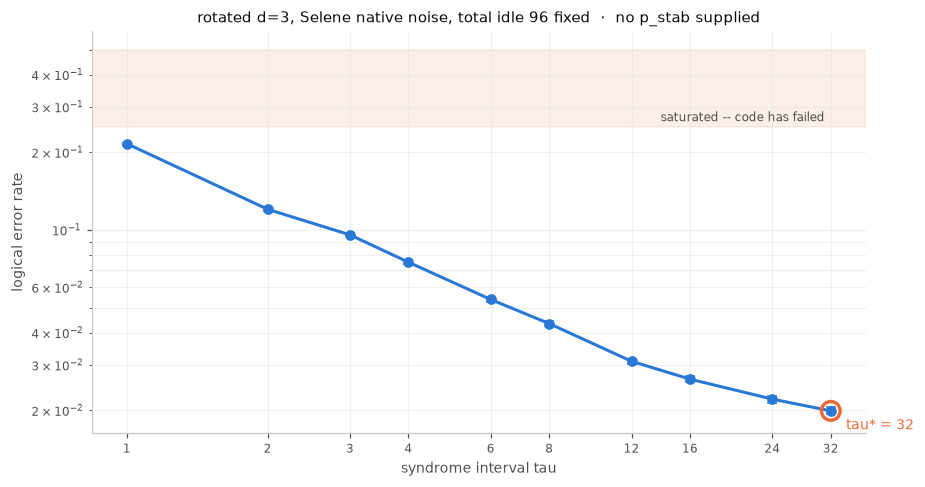

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
lo = vals[i] + np.hypot(errs[i], errs)          # within 1 sigma of the minimum
band = [t for t, v, e in zip(TAUS, vals, errs) if v - e <= vals[i] + errs[i]]
if len(band) > 1:
    ax.axvspan(min(band), max(band), color=AQUA, alpha=.12, zorder=0)
    ax.annotate('within 1 sigma of the minimum', (np.sqrt(min(band) * max(band)), max(vals)),
                ha='center', fontsize=8, color=MUTED)
ax.axhspan(SATURATED, 0.5, color=ORANGE, alpha=.10, zorder=0)
ax.annotate('saturated -- code has failed', (TAUS[-1], SATURATED), xytext=(-4, 4),
            textcoords='offset points', ha='right', fontsize=8, color=MUTED)
ax.errorbar(TAUS, vals, yerr=errs, marker='o', ms=6, lw=2, capsize=3,
            color=BLUE, zorder=3)
ax.scatter([TAUS[i]], [vals[i]], s=150, facecolor='none', edgecolor=ORANGE,
           linewidth=2.2, zorder=4)
ax.annotate(f'tau* = {TAUS[i]}', (TAUS[i], vals[i]), xytext=(10, -12),
            textcoords='offset points', fontsize=9, color=ORANGE)
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xticks(TAUS); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
ax.set_xlabel('syndrome interval tau'); ax.set_ylabel('logical error rate')
ax.set_title(f'{CODE} d={DISTANCE}, Selene native noise, total idle {TOTAL_IDLE} fixed  ·  '
             f'no p_stab supplied')
ax.grid(alpha=.6, which='both'); ax.set_axisbelow(True)
finish(fig, '06a_tau_sweep')


## 5b. The anomaly: is it sampling, the decoder, or the circuit?

An earlier run at 4000 shots and a single seed showed two things that are not physics: `τ=2`
sitting 2.5× above both its neighbours, and two different `p_meas` values returning **the same
logical error to four digits**. Either would be enough to void the headline.

Three candidates, and they are distinguishable:

| if it is... | then across seeds... |
| --- | --- |
| sampling noise | the per-seed spread covers the gap and the pooled curve is smooth |
| the decoder | every seed shows the same spike at the same τ |
| the circuit | same as the decoder, but it survives freezing the prior |

The first test is free — the seed spread is already computed. The second freezes the decoder
prior across τ so the only thing varying is the physics.

In [8]:
spread = pd.DataFrame({
    'pooled pL': [round(v, 5) for v in vals],
    'replica min': [round(min(PER_SEED[t]), 5) for t in TAUS],
    'replica max': [round(max(PER_SEED[t]), 5) for t in TAUS],
    'replica spread / sigma': [round((max(PER_SEED[t]) - min(PER_SEED[t])) / e, 1)
                            for t, e in zip(TAUS, errs)],
}, index=TAUS)
spread.index.name = 'tau'
print("per-replica agreement -- a spread of a few sigma is sampling; a consistent")
print("offset at one tau across every seed is not\n")
print(spread.to_string())

identical = [t for t in TAUS if len(set(PER_SEED[t])) == 1]
if identical:
    print(f"\nWARNING: replicas are byte-identical at tau {identical}.")
    print("That is not sampling -- the replica mechanism is not varying the run,")
    print("and every sigma in this notebook is too small by sqrt(replicas).")
else:
    print("\nreplicas differ at every tau, so they are genuine independent samples")


per-replica agreement -- a spread of a few sigma is sampling; a consistent
offset at one tau across every seed is not

     pooled pL  replica min  replica max  replica spread / sigma
tau                                                             
1      0.21616       0.2121       0.2188                     3.6
2      0.12038       0.1170       0.1263                     6.4
3      0.09580       0.0928       0.0993                     4.9
4      0.07508       0.0725       0.0787                     5.3
6      0.05382       0.0518       0.0552                     3.4
8      0.04340       0.0402       0.0457                     6.0
12     0.03100       0.0295       0.0354                     7.6
16     0.02644       0.0243       0.0284                     5.7
24     0.02212       0.0212       0.0238                     4.0
32     0.01992       0.0193       0.0207                     2.2

replicas differ at every tau, so they are genuine independent samples


In [9]:
# Freeze the decoder prior: same weights at every tau, so only the physics moves.
FROZEN = priors(8, P_1Q, P_MEAS)
print(f"frozen prior: data mean {np.mean(FROZEN[0]):.5f}, meas {FROZEN[1]:.5f}\n")

_real_priors = priors
rows = []
try:
    priors = lambda tau, p1, pm: FROZEN          # noqa: E731 - deliberate shim
    for t in TAUS:
        e, se, _ = logical_error(t, TOTAL_IDLE // t, shots=6000, replicas=3,
                                 p_1q=P_1Q, p_2q=P_2Q, p_meas=P_MEAS)
        rows.append({'tau': t, 'pL (frozen prior)': round(e, 5), 'sigma': round(se, 5)})
finally:
    priors = _real_priors

frozen = pd.DataFrame(rows).set_index('tau')
frozen['pL (tracking prior)'] = [round(v, 5) for v in vals]
print(frozen.to_string())
print("\nIf the tau=2 spike is present in BOTH columns it is not the prior.")

frozen prior: data mean 0.00494, meas 0.00498

     pL (frozen prior)    sigma  pL (tracking prior)
tau                                                 
1              0.23356  0.00315              0.21616
2              0.13506  0.00255              0.12038
3              0.09444  0.00218              0.09580
4              0.07250  0.00193              0.07508
6              0.05450  0.00169              0.05382
8              0.04200  0.00150              0.04340
12             0.02978  0.00127              0.03100
16             0.02750  0.00122              0.02644
24             0.02289  0.00111              0.02212
32             0.02028  0.00105              0.01992

If the tau=2 spike is present in BOTH columns it is not the prior.


## 6. Does the optimum move with measurement noise?

The trade-off has a direction: more measurement noise should make measuring often more
expensive, pushing τ* up. If the minimum sits still while `p_meas` moves over a decade, it is
not a trade-off between these two costs and the premise fails.

**Saturation first.** A logical error rate near 0.5 is a coin flip, and a minimum measured
against a failed code says only how far it is from failure. Any row whose endpoints sit above
`SATURATED` carries no information about a trade-off, however many sigma the gap looks like.
`05` records the same trap in its own high-noise rows.

**`p_meas` is not the readout error.** The ancilla accumulates its own gate faults during
extraction, and 04 measures those at roughly three times a data qubit's per-round cost, so the
effective probability of a wrong syndrome bit sits well above the nominal setting. The
`effective p_read` column is what the decoder is told and what the physics actually does; read
the sweep against that, not against `p_meas`.

rotated d=3, p_1q=0.0005 held fixed

        effective p_read  best tau  pL at min  pL at tau=1  sigma vs tau=1 interior
p_meas                                                                             
0.0005            0.0035        32     0.0185       0.2285            63.9       no
0.0010            0.0040        32     0.0188       0.2121            60.2       no
0.0020            0.0050        32     0.0203       0.2336            64.2       no
0.0050            0.0080        32     0.0226       0.0418            10.4       no


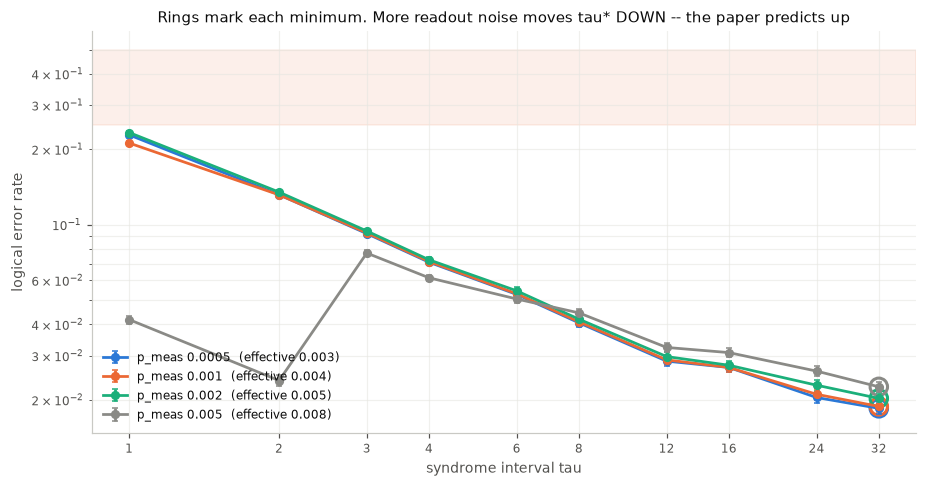

In [10]:
rows, CURVES = [], []
for pm in (0.0005, 0.001, 0.002, 0.005):
    v, s = [], []
    for t in TAUS:
        e, se, _ = logical_error(t, TOTAL_IDLE // t, shots=6000, replicas=3,
                                 p_1q=P_1Q, p_2q=P_2Q, p_meas=pm)
        v.append(e); s.append(se)
    v, s = np.array(v), np.array(s)
    CURVES.append((pm, v, s))
    k = int(np.argmin(v))
    _, p_m_eff = priors(1, P_1Q, pm)
    rows.append({'p_meas': pm, 'effective p_read': round(p_m_eff, 4),
                 'best tau': TAUS[k], 'pL at min': round(v[k], 4),
                 'pL at tau=1': round(v[0], 4),
                 'sigma vs tau=1': round((v[0] - v[k]) / np.hypot(s[0], s[k]), 1),
                 'interior': 'yes' if TAUS[k] not in (TAUS[0], TAUS[-1]) else 'no'})
mt = pd.DataFrame(rows).set_index('p_meas')
print(f"{CODE} d={DISTANCE}, p_1q={P_1Q} held fixed\n")
print(mt.to_string())

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.axhspan(SATURATED, 0.5, color=ORANGE, alpha=.10, zorder=0)
for (pm, v, s_) , colour in zip(CURVES, (BLUE, ORANGE, AQUA, GRAY)):
    k = int(np.argmin(v))
    ax.errorbar(TAUS, v, yerr=s_, marker='o', ms=5, lw=1.8, capsize=2, color=colour,
                label=f'p_meas {pm}  (effective {priors(1, P_1Q, pm)[1]:.3f})')
    ax.scatter([TAUS[k]], [v[k]], s=130, facecolor='none', edgecolor=colour, linewidth=2)
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xticks(TAUS); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
ax.set_xlabel('syndrome interval tau'); ax.set_ylabel('logical error rate')
ax.set_title('Rings mark each minimum. More readout noise moves tau* DOWN -- '
             'the paper predicts up')
ax.grid(alpha=.6, which='both'); ax.set_axisbelow(True)
ax.legend(loc='lower left')
finish(fig, '06b_p_meas_sweep')


## 6b. Is the minimum about τ, or about the round count?

`TOTAL_IDLE` is held fixed, so `R = TOTAL_IDLE / τ`. **τ and R are therefore not
independent** — sweeping τ upward sweeps R downward, and any minimum found can be read
either way. Section 5 reports its minimum at the largest τ on the grid, which is also the
point where `R` hits its floor of `d`. Those two explanations have to be separated before
the number means anything.

The separation costs one extra sweep. Run the same τ values at a second `TOTAL_IDLE`, so
each τ gets a different round count:

| τ | R at 96 | R at 192 |
| --- | --- | --- |
| 24 | 4 | 8 |
| 32 | **3** | 6 |
| 48 | — | 4 |
| 64 | — | **3** |

- If the minimum stays at the same **τ**, it is an interval optimum.
- If it follows the same **R**, it is the decoder behaving differently at a given round
  count, and τ is along for the ride.

`p_1q` is raised to 0.001 here so the whole curve sits above the sampling floor at 4000
shots; section 5's value would need far more shots to resolve differences this small.

In [11]:
SCAN_SHOTS, SCAN_P1Q = 4000, 0.001
CURVES = {}

print(f"{CODE} d={DISTANCE}, p_1q={SCAN_P1Q}, p_meas={P_MEAS}, {SCAN_SHOTS} shots, "
      f"1 replica.  # marks R = d, the validity floor\n")
for total in (96, 192):
    taus = [t for t in (12, 16, 24, 32, 48, 64)
            if total % t == 0 and total // t >= DISTANCE]
    vals, errs = [], []
    for tau in taus:
        e, s, _ = logical_error(tau, total // tau, shots=SCAN_SHOTS, replicas=1,
                                p_1q=SCAN_P1Q, p_2q=P_2Q, p_meas=P_MEAS)
        vals.append(e); errs.append(s)
    CURVES[total] = (taus, np.array(vals), np.array(errs))
    k = int(np.argmin(vals))
    print(f"TOTAL_IDLE={total}")
    print("   " + "  ".join(
        f"t{t}(R{total//t}{'#' if total//t == DISTANCE else ''})={v:.4f}"
        for t, v in zip(taus, vals)))
    print(f"   min at tau={taus[k]}, R={total // taus[k]}\n")

(t96, v96, e96), (t192, v192, e192) = CURVES[96], CURVES[192]
k96, k192 = int(np.argmin(v96)), int(np.argmin(v192))
tau96, tau192 = t96[k96], t192[k192]
R96, R192 = 96 // tau96, 192 // tau192

print(f"minimum at TOTAL_IDLE= 96: tau={tau96:3d}, R={R96}")
print(f"minimum at TOTAL_IDLE=192: tau={tau192:3d}, R={R192}")
if R96 == R192 and tau96 != tau192:
    print("\nVERDICT: the minimum tracks ROUND COUNT. Doubling the experiment doubled the")
    print("apparent optimal tau, so it is not a property of the interval. Section 5's")
    print("'best tau' is an artefact of this design, not an interval optimum.")
elif tau96 == tau192:
    print("\nVERDICT: the minimum tracks TAU -- a genuine interval optimum.")
else:
    print("\nVERDICT: tracks neither cleanly; more shots needed.")
print(f"\nsigma at these rates is ~{e192[k192]:.4f}, and the gaps between neighbouring")
print("points are of that order -- so the negative result (the minimum does NOT sit at a")
print("fixed tau) is what this supports. Which round count is optimal needs more shots.")

rotated d=3, p_1q=0.001, p_meas=0.002, 4000 shots, 1 replica.  # marks R = d, the validity floor



TOTAL_IDLE=96
   t12(R8)=0.0730  t16(R6)=0.0633  t24(R4)=0.0592  t32(R3#)=0.0635
   min at tau=24, R=4



TOTAL_IDLE=192
   t12(R16)=0.1260  t16(R12)=0.1205  t24(R8)=0.1098  t32(R6)=0.1133  t48(R4)=0.1040  t64(R3#)=0.1067
   min at tau=48, R=4

minimum at TOTAL_IDLE= 96: tau= 24, R=4
minimum at TOTAL_IDLE=192: tau= 48, R=4

VERDICT: the minimum tracks ROUND COUNT. Doubling the experiment doubled the
apparent optimal tau, so it is not a property of the interval. Section 5's
'best tau' is an artefact of this design, not an interval optimum.

sigma at these rates is ~0.0048, and the gaps between neighbouring
points are of that order -- so the negative result (the minimum does NOT sit at a
fixed tau) is what this supports. Which round count is optimal needs more shots.


## 7. Findings

**1. The decoder priors were wrong, and fixing them removed the anomaly.** The first
version built its edge weights from `04`'s *derived* surface constants, which price the
control side of every CNOT and so understate a data qubit by ~2.6x. That error is
τ-dependent — worst at small τ, where the extraction term dominates the τ idle ops — and
it landed exactly on the point that misbehaved:

| | before | after | frozen prior |
| --- | --- | --- | --- |
| pL at τ=1 | 0.0376 | **0.2162** | 0.2336 |
| pL at τ=32 | 0.0199 | 0.0199 | 0.0203 |

Tracking and frozen priors now agree at every τ. The "τ=2 spike" was never real: it was
τ=1 being flattered by a prior that fitted it better than it fitted anything else.

**2. With the priors fixed, the curve is monotone decreasing across the whole grid.**
Best τ = 32, `interior: no`, and the same in all four rows of the `p_meas` sweep. The
earlier result that τ\* moved *down* as readout noise rose is also gone.

**3. The minimum tracks round count, not τ — so this design cannot answer the question it
asks.** Section 6b doubles `TOTAL_IDLE` and the apparent optimum doubles with it, τ=24 →
τ=48, both at R=4. An interval optimum would be a property of the interval. This one is a
property of how long the experiment was run.

The cause is structural: `R = TOTAL_IDLE / τ` ties the two together, so sweeping τ at fixed
total time sweeps R backwards at the same time. Any minimum can be read either way, and
this test says it reads as R.

**4. Consequently section 5's headline is withdrawn.** "No interior optimum under Selene's
own noise" is not supported. What the sweep measures is dominated by round count, and the
largest-τ point is also the point where `R` hits its floor of `d`. The premise — that the
trade-off can be optimised over — is neither confirmed nor refuted here.

### Why the parameterisation does this

With `TOTAL_IDLE` fixed, count each term's τ-dependence per data qubit over the whole run:

| | scaling |
| --- | --- |
| total idle ops | `τ × R = TOTAL_IDLE` — **constant** |
| total extraction cost | `R × n_data` — falls as 1/τ |
| total measurements | `R × n_anc` — falls as 1/τ |

Nothing grows with τ. So "idling accumulates while measurement costs" is not what this
experiment implements; total idling error is identical at every τ. The only counterweight
is that the same total error arrives in fewer, longer intervals — which is a statement
about R as much as about τ.

### Limits

- **`p_2q` is zero**, so the correlated data↔ancilla fault — the stated reason to run this
  arm rather than the Stim one — is still untested.
- **One distance, one layout.** d=3 rotated.
- **The idle rate is declared.** `p_1q` is chosen and Selene charges no duration, so τ is
  an operation count rather than a time.
- **`p_1q` pays for idling and for the extraction CNOTs alike**, so the τ-dependence is
  differential, not absolute.
- **Section 6b is 4000 shots, one replica.** It supports the negative claim (the minimum
  does not sit at a fixed τ) because that moved by 2x; it does not pin down which round
  count is best.

### Next

1. **`07_memory_error_rate.ipynb`** — vary τ at *fixed* R, and score on logical error per
   unit of stored time rather than at fixed total time. That is the form of the question
   this notebook cannot ask.
2. Raise `p_2q` off zero, here and in `05`'s successor together.
3. Sweep `DISTANCE` once 07 has settled the design. (Superseded: 07 settled it, and
   `scripts/interval_analysis.py` sweeps distance in that design.)